# 1. Dataset Overview

Source, problem definition, columns, and dataset dimensions.

### Important laibraries

In [2]:
import pandas as pd
from pathlib import Path

In [4]:
df = pd.read_csv("data/Metro_Interstate_Traffic_Volume.csv")

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nData types:")
print(df.info())

Dataset shape: (48204, 9)

Column names:
['holiday', 'temp', 'rain_1h', 'snow_1h', 'clouds_all', 'weather_main', 'weather_description', 'date_time', 'traffic_volume']

First five rows:


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918



Data types:
holiday                    str
temp                   float64
rain_1h                float64
snow_1h                float64
clouds_all               int64
weather_main               str
weather_description        str
date_time                  str
traffic_volume           int64
dtype: object

Data types:
<class 'pandas.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     str    
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  str    
 6   weather_description  48204 non-null  str    
 7   date_time            48204 non-null  str    
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), str(

### 2. Data Quality Assessment

Before cleaning the dataset, I will assess missing values, duplicate records, timestamp validity, chronological ordering, and sampling frequency. These checks will help identify potential problems that could affect the reliability of the exploratory analysis and traffic-volume forecasting.

In [5]:

# Check missing values in each column
print("Missing values per column:")
print(df.isnull().sum())

print("\nMissing values as percentages:")
print((df.isnull().mean() * 100).round(2))

# Check duplicate rows
print("\nNumber of fully duplicated rows:")
print(df.duplicated().sum())

# Check duplicate timestamps
print("\nNumber of duplicated timestamps:")
print(df["date_time"].duplicated().sum())


Missing values per column:
holiday                48143
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
date_time                  0
traffic_volume             0
dtype: int64

Missing values as percentages:
holiday                99.87
temp                    0.00
rain_1h                 0.00
snow_1h                 0.00
clouds_all              0.00
weather_main            0.00
weather_description     0.00
date_time               0.00
traffic_volume          0.00
dtype: float64

Number of fully duplicated rows:
17

Number of duplicated timestamps:
7629


In [6]:

# Convert timestamps into datetime values
df["date_time"] = pd.to_datetime(
    df["date_time"],
    errors="coerce"
)

# Check timestamps that could not be converted
print("Invalid or missing timestamps:",
      df["date_time"].isna().sum())

# Check chronological ordering
print("Already in chronological order:",
      df["date_time"].is_monotonic_increasing)

# Display earliest and latest timestamps
print("Earliest timestamp:", df["date_time"].min())
print("Latest timestamp:", df["date_time"].max())


Invalid or missing timestamps: 0
Already in chronological order: True
Earliest timestamp: 2012-10-02 09:00:00
Latest timestamp: 2018-09-30 23:00:00


In [7]:

# Sort a separate timestamp series for reliable interval analysis
timestamps = df["date_time"].dropna().sort_values()

# Calculate the time difference between consecutive observations
time_gaps = timestamps.diff().dropna()

print("Most common time intervals:")
print(time_gaps.value_counts().head(10))

print("\nNumber of intervals equal to one hour:",
      (time_gaps == pd.Timedelta(hours=1)).sum())

print("\nNumber of intervals longer than one hour:",
      (time_gaps > pd.Timedelta(hours=1)).sum())

print("\nNumber of intervals shorter than one hour:",
      (time_gaps < pd.Timedelta(hours=1)).sum())


Most common time intervals:
date_time
0 days 01:00:00    37986
0 days 00:00:00     7629
0 days 02:00:00     2192
0 days 03:00:00      201
0 days 04:00:00       59
0 days 05:00:00       33
0 days 06:00:00       17
0 days 08:00:00       13
0 days 10:00:00       13
0 days 09:00:00       12
Name: count, dtype: int64

Number of intervals equal to one hour: 37986

Number of intervals longer than one hour: 2588

Number of intervals shorter than one hour: 7629


In [8]:

# Show examples of repeated timestamps
repeated = df[
    df["date_time"].duplicated(keep=False)
].sort_values("date_time")

print("Rows involved in repeated timestamps:",
      len(repeated))

display(repeated.head(12))

# Count how many unique traffic-volume values occur
# at each timestamp
traffic_values_per_time = (
    df.groupby("date_time")["traffic_volume"]
      .nunique()
)

print("\nTimestamps with multiple traffic-volume values:",
      (traffic_values_per_time > 1).sum())

print("Timestamps with repeated records but one traffic-volume value:",
      ((df["date_time"].duplicated(keep=False)).sum()))


Rows involved in repeated timestamps: 13074


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
178,NaN,281.25,0.0,0.0,99,Rain,light rain,2012-10-10 07:00:00,6793
179,NaN,281.25,0.0,0.0,99,Drizzle,light intensity drizzle,2012-10-10 07:00:00,6793
180,NaN,280.10,0.0,0.0,99,Rain,light rain,2012-10-10 08:00:00,6283
181,NaN,280.10,0.0,0.0,99,Drizzle,light intensity drizzle,2012-10-10 08:00:00,6283
182,NaN,279.61,0.0,0.0,99,Rain,light rain,2012-10-10 09:00:00,5680
183,NaN,279.61,0.0,0.0,99,Drizzle,light intensity drizzle,2012-10-10 09:00:00,5680
269,NaN,282.43,0.0,0.0,57,Drizzle,light intensity drizzle,2012-10-14 09:00:00,2685
270,NaN,282.43,0.0,0.0,57,Mist,mist,2012-10-14 09:00:00,2685
271,NaN,282.43,0.0,0.0,57,Haze,haze,2012-10-14 09:00:00,2685
272,NaN,282.33,0.0,0.0,57,Drizzle,light intensity drizzle,2012-10-14 10:00:00,3370



Timestamps with multiple traffic-volume values: 0
Timestamps with repeated records but one traffic-volume value: 13074


In [9]:

# Count distinct timestamps that occur more than once
timestamp_counts = df["date_time"].value_counts()

print(
    "Distinct timestamps occurring more than once:",
    (timestamp_counts > 1).sum()
)

# Check whether records sharing a timestamp differ in other columns
duplicate_groups = df[
    df["date_time"].duplicated(keep=False)
].groupby("date_time")

conflicting_groups = sum(
    1 for _, group in duplicate_groups
    if len(group.drop(columns="date_time").drop_duplicates()) > 1
)

print("Repeated timestamps with differing other-column values:",
      conflicting_groups)

# Check exact duplicate rows
print("Exact duplicate rows:", df.duplicated().sum())


Distinct timestamps occurring more than once: 5445
Repeated timestamps with differing other-column values: 5430
Exact duplicate rows: 17


In [10]:

# Select a few timestamps that have different records
repeated = df[
    df["date_time"].duplicated(keep=False)
].sort_values("date_time")

example_times = (
    repeated.groupby("date_time")
    .filter(
        lambda group: len(group.drop(columns="date_time")
                          .drop_duplicates()) > 1
    )["date_time"]
    .drop_duplicates()
    .head(3)
)

for timestamp in example_times:
    print(f"\nTimestamp: {timestamp}")
    display(
        df[df["date_time"] == timestamp]
    )



Timestamp: 2012-10-10 07:00:00


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
178,NaN,281.25,0.0,0.0,99,Rain,light rain,2012-10-10 07:00:00,6793
179,NaN,281.25,0.0,0.0,99,Drizzle,light intensity drizzle,2012-10-10 07:00:00,6793



Timestamp: 2012-10-10 08:00:00


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
180,NaN,280.1,0.0,0.0,99,Rain,light rain,2012-10-10 08:00:00,6283
181,NaN,280.1,0.0,0.0,99,Drizzle,light intensity drizzle,2012-10-10 08:00:00,6283



Timestamp: 2012-10-10 09:00:00


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
182,NaN,279.61,0.0,0.0,99,Rain,light rain,2012-10-10 09:00:00,5680
183,NaN,279.61,0.0,0.0,99,Drizzle,light intensity drizzle,2012-10-10 09:00:00,5680


In [11]:
# Numerical columns we want to compare
numeric_cols = [
    "temp",
    "rain_1h",
    "snow_1h",
    "clouds_all",
    "traffic_volume"
]

# Count timestamps where each numerical column has
# more than one distinct value
for col in numeric_cols:
    unique_counts = df.groupby("date_time")[col].nunique()
    conflicts = (unique_counts > 1).sum()

    print(f"{col}: {conflicts} timestamps with conflicting values")


temp: 78 timestamps with conflicting values
rain_1h: 9 timestamps with conflicting values
snow_1h: 0 timestamps with conflicting values
clouds_all: 32 timestamps with conflicting values
traffic_volume: 0 timestamps with conflicting values


In [12]:
# Find a timestamp where temperature differs
temp_counts = df.groupby("date_time")["temp"].nunique()
example_time = temp_counts[temp_counts > 1].index[0]

print("Example timestamp:", example_time)

display(
    df[df["date_time"] == example_time][
        ["date_time", "temp", "rain_1h", "clouds_all",
         "weather_main", "weather_description", "traffic_volume"]
    ]
)

Example timestamp: 2012-11-04 01:00:00


,date_time,temp,rain_1h,clouds_all,weather_main,weather_description,traffic_volume
878,2012-11-04 01:00:00,275.60,0.0,90,Clouds,overcast clouds,730
879,2012-11-04 01:00:00,275.77,0.0,90,Clouds,overcast clouds,730


In [13]:

# Preserve the original dataset
df_original = df.copy()

# Remove exact duplicate rows
df_clean = df.drop_duplicates().copy()

# Define a function to select the most frequent non-missing value
def most_frequent_value(series):
    values = series.dropna()

    if values.empty:
        return None

    return values.mode().iloc[0]

# Consolidate records to one row per timestamp
df_clean = (
    df_clean.groupby("date_time", as_index=False)
    .agg({
        "holiday": most_frequent_value,
        "temp": "mean",
        "rain_1h": "mean",
        "snow_1h": "mean",
        "clouds_all": "mean",
        "weather_main": most_frequent_value,
        "weather_description": most_frequent_value,
        "traffic_volume": "first"
    })
    .sort_values("date_time")
    .reset_index(drop=True)
)

print("Original rows:", len(df_original))
print("Cleaned rows:", len(df_clean))
print("Remaining duplicate timestamps:",
      df_clean["date_time"].duplicated().sum())
print("Missing values after consolidation:")
print(df_clean.isnull().sum())


Original rows: 48204
Cleaned rows: 40575
Remaining duplicate timestamps: 0
Missing values after consolidation:
date_time                  0
holiday                40522
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
traffic_volume             0
dtype: int64


In [14]:

# Calculate the time difference between consecutive cleaned records
gaps = df_clean["date_time"].diff()

print("Most common intervals after cleaning:")
print(gaps.value_counts().head(10))

# Identify intervals longer than one hour
long_gaps = gaps[gaps > pd.Timedelta(hours=1)]

print("\nNumber of intervals longer than one hour:",
      len(long_gaps))

print("\nTotal hours missing between observed timestamps:",
      int((long_gaps / pd.Timedelta(hours=1) - 1).sum()))


Most common intervals after cleaning:
date_time
0 days 01:00:00    37986
0 days 02:00:00     2192
0 days 03:00:00      201
0 days 04:00:00       59
0 days 05:00:00       33
0 days 06:00:00       17
0 days 08:00:00       13
0 days 10:00:00       13
0 days 09:00:00       12
0 days 07:00:00       10
Name: count, dtype: int64

Number of intervals longer than one hour: 2588

Total hours missing between observed timestamps: 11976


### Step 2.9: Investigating Missing Time Intervals

In this step, I will identify where the largest gaps occur in the time series. This will help me understand whether missing hourly observations are spread throughout the dataset or concentrated in particular periods. I will use this information to decide how to prepare the data for time-series forecasting without inventing traffic-volume values.

In [15]:
# Calculate the time difference between consecutive records
time_diff = df_clean["date_time"].diff()

# Find gaps longer than one hour
gap_positions = time_diff[time_diff > pd.Timedelta(hours=1)].index

# Describe each gap
gap_details = pd.DataFrame({
    "last_observed_time": df_clean.loc[gap_positions - 1, "date_time"].values,
    "next_observed_time": df_clean.loc[gap_positions, "date_time"].values,
    "gap_hours": (
        df_clean.loc[gap_positions, "date_time"].values -
        df_clean.loc[gap_positions - 1, "date_time"].values
    ) / pd.Timedelta(hours=1)
})

gap_details["missing_hours"] = gap_details["gap_hours"] - 1

# Show the 10 largest gaps
print("Ten largest gaps in the time series:")
print(gap_details.sort_values("gap_hours", ascending=False).head(10).to_string(index=False))

Ten largest gaps in the time series:
 last_observed_time  next_observed_time  gap_hours  missing_hours
2014-08-08 01:00:00 2015-06-11 20:00:00     7387.0         7386.0
2013-10-27 01:00:00 2013-11-06 04:00:00      243.0          242.0
2015-06-14 20:00:00 2015-06-19 18:00:00      118.0          117.0
2014-04-29 08:00:00 2014-05-04 05:00:00      117.0          116.0
2015-10-23 11:00:00 2015-10-27 08:00:00       93.0           92.0
2014-07-27 16:00:00 2014-07-30 09:00:00       65.0           64.0
2013-08-31 00:00:00 2013-09-01 23:00:00       47.0           46.0
2015-06-22 18:00:00 2015-06-24 04:00:00       34.0           33.0
2014-08-02 02:00:00 2014-08-03 11:00:00       33.0           32.0
2013-09-03 02:00:00 2013-09-04 08:00:00       30.0           29.0


The output shows that missing observations are not evenly distributed. Most importantly, there is an unusually large gap between August 8, 2014, and June 11, 2015.

That gap is 7,386 missing hours, or about 308 days. This is much larger than the other gaps, which range from 29 to 242 missing hours among the ten largest gaps shown.

This tells me that:
- The dataset does not contain a continuous hourly record.
- The largest gap could significantly affect forecasting if we treat the data as one uninterrupted time series.
- I should not fill such a long gap with invented traffic values.
- I need to investigate whether the dataset contains separate periods of observations before deciding how to prepare it for forecasting.

### Step 2.10: Identifying Continuous Observation Periods

In this step, I will divide the dataset into continuous observation periods. Whenever the gap between consecutive records is longer than one hour, I will mark the beginning of a new period. I will then compare the lengths of these periods to understand how much continuous hourly data is available for forecasting. I will not fill missing traffic values with zero.

In [16]:
# Calculate the time difference between consecutive records
time_diff = df_clean["date_time"].diff()

# Start a new period whenever the gap is longer than one hour
new_period = time_diff.isna() | (time_diff > pd.Timedelta(hours=1))
df_clean["period_id"] = new_period.cumsum()

# Summarize each period
period_summary = (
    df_clean.groupby("period_id")
    .agg(
        start_time=("date_time", "min"),
        end_time=("date_time", "max"),
        observations=("date_time", "count")
    )
    .reset_index()
)

period_summary["duration_days"] = (
    (period_summary["end_time"] - period_summary["start_time"])
    .dt.total_seconds() / 86400
)

print("Number of continuous periods:", len(period_summary))
print("\nTen longest continuous periods:")
print(
    period_summary.sort_values("observations", ascending=False)
    .head(10)
    .to_string(index=False)
)

Number of continuous periods: 2589

Ten longest continuous periods:
 period_id          start_time            end_time  observations  duration_days
      2565 2017-04-13 10:00:00 2017-07-02 04:00:00          1915      79.750000
      2587 2018-06-02 03:00:00 2018-08-07 06:00:00          1588      66.125000
      2556 2016-12-18 19:00:00 2017-02-13 15:00:00          1365      56.833333
      2515 2016-07-13 18:00:00 2016-08-24 16:00:00          1007      41.916667
      2571 2017-09-28 00:00:00 2017-11-08 01:00:00           986      41.041667
      2589 2018-08-23 03:00:00 2018-09-30 23:00:00           933      38.833333
      2579 2018-01-31 03:00:00 2018-03-10 01:00:00           911      37.916667
       779 2014-01-26 09:00:00 2014-03-04 14:00:00           894      37.208333
      2585 2018-03-29 03:00:00 2018-05-05 01:00:00           887      36.916667
      2568 2017-07-10 16:00:00 2017-08-16 03:00:00           876      36.458333


I found 2,589 continuous observation periods in my cleaned dataset. This means the data is divided into many separate periods because some timestamps are missing between consecutive records.

The longest period contains 1,915 observations over approximately 79.75 days, from April 13, 2017, to July 2, 2017. The other long periods are also limited to a few weeks or months.

This tells me that I cannot treat the entire dataset as one continuous hourly time series without addressing the gaps. I will preserve the original timestamps and avoid filling missing traffic-volume values with zero. Before forecasting, I will investigate the observation frequency and select a suitable continuous period or approach for handling the gaps.

### Step 2.11: Investigating Missing Holiday Values

In this step, I will examine the recorded values in the `holiday` column. I will count the occurrences of each holiday label and check how many values are missing. This will help me understand the available holiday information before choosing an appropriate strategy for handling the missing values.

In [17]:
print("Holiday value counts, including missing values:")
print(df_original["holiday"].value_counts(dropna=False))

print("\nNumber of non-missing holiday values:")
print(df_original["holiday"].notna().sum())

print("\nNumber of distinct recorded holiday labels:")
print(df_original["holiday"].nunique())

Holiday value counts, including missing values:
holiday
NaN                          48143
Labor Day                        7
Thanksgiving Day                 6
Christmas Day                    6
New Years Day                    6
Martin Luther King Jr Day        6
Columbus Day                     5
Veterans Day                     5
Washingtons Birthday             5
Memorial Day                     5
Independence Day                 5
State Fair                       5
Name: count, dtype: int64

Number of non-missing holiday values:
61

Number of distinct recorded holiday labels:
11


### Step 2.12: Examining Recorded Holidays and Traffic Volume

In this step, I will examine the dates, holiday labels, and traffic volumes for observations where the `holiday` column is not missing. This will help me understand how the recorded holiday information aligns with the timestamps and whether it may be useful for analyzing traffic patterns.

In [18]:
# Select rows where a holiday is recorded
holiday_rows = df_original[df_original["holiday"].notna()].copy()

print("Recorded holiday observations:")
print(
    holiday_rows[["date_time", "holiday", "traffic_volume"]]
    .sort_values("date_time")
    .to_string(index=False)
)

Recorded holiday observations:
 date_time                   holiday  traffic_volume
2012-10-08              Columbus Day             455
2012-11-12              Veterans Day            1000
2012-11-22          Thanksgiving Day             919
2012-12-25             Christmas Day             803
2013-01-01             New Years Day            1439
2013-02-18      Washingtons Birthday             556
2013-05-27              Memorial Day             863
2013-07-04          Independence Day            1060
2013-08-22                State Fair             661
2013-09-02                 Labor Day            1041
2013-10-14              Columbus Day             615
2013-11-11              Veterans Day             514
2013-11-28          Thanksgiving Day             929
2013-12-25             Christmas Day             712
2014-01-01             New Years Day            1395
2014-01-20 Martin Luther King Jr Day             480
2014-02-17      Washingtons Birthday             583
2014-05-26     

### Interpretation of Recorded Holiday Observations

I observed that the recorded holiday dates have different traffic-volume values. For example, the dataset records a traffic volume of 455 on Columbus Day in 2012, 919 on Thanksgiving Day in 2012, and 1,439 on New Year's Day in 2013.

These observations suggest that traffic volume can vary on holidays. However, I cannot conclude that holidays always have lower traffic because I have not yet compared these observations with traffic volumes on ordinary days at comparable hours.

I also noticed that some holiday observations appear more than once, such as Labor Day on September 3, 2018. This is expected because the dataset can contain multiple hourly observations on the same holiday date, although I will check whether the repeated rows represent different timestamps or duplicate records.

The holiday column may be useful for understanding traffic patterns, but I need to investigate its relationship with the dates before deciding how to handle its missing values.

### Step 2.13: Checking Holiday Dates and Timestamps

In this step, I will compare the dates recorded in the `holiday` column with the dates in the `date_time` column. I will check how many distinct dates have holiday labels and whether each recorded holiday label appears on a single date or multiple dates. This will help me understand how the holiday information is represented in the dataset before deciding how to handle missing values.

In [19]:
holiday_rows = df_original[df_original["holiday"].notna()].copy()

holiday_rows["date"] = pd.to_datetime(holiday_rows["date_time"]).dt.date

print("Number of rows with recorded holidays:",
      len(holiday_rows))

print("Number of distinct dates with recorded holidays:",
      holiday_rows["date"].nunique())

print("\nDistinct dates per holiday label:")
print(
    holiday_rows.groupby("holiday")["date"]
    .nunique()
    .sort_values(ascending=False)
)

Number of rows with recorded holidays: 61
Number of distinct dates with recorded holidays: 53

Distinct dates per holiday label:
holiday
Christmas Day                5
Columbus Day                 5
Independence Day             5
Labor Day                    5
Memorial Day                 5
New Years Day                5
State Fair                   5
Veterans Day                 5
Thanksgiving Day             5
Washingtons Birthday         5
Martin Luther King Jr Day    3
Name: date, dtype: int64


### Interpretation of Holiday Dates and Timestamps

I found 61 rows with recorded holiday labels, covering 53 distinct dates. The holiday labels appear across multiple years, with most labels occurring on five distinct dates and Martin Luther King Jr Day occurring on three dates.

This confirms that the holiday information is recorded for only a small portion of the dataset. However, these results do not prove that missing holiday values mean ordinary days without holidays.

I will therefore avoid automatically replacing all missing holiday values with `No Holiday`. Instead, I will investigate whether the recorded holiday dates follow a recognizable pattern and whether I can use the timestamps to identify holidays reliably.

### Step 2.14: Examining the Time-of-Day Coverage of Holiday Records

In this step, I will examine the hours at which holiday observations are recorded. This will help me determine whether the holiday column identifies only selected hourly observations on a holiday or whether it labels all available observations throughout a holiday date. This distinction is important before deciding how to handle missing holiday values.

In [20]:
holiday_rows = df_original[df_original["holiday"].notna()].copy()

holiday_rows["date_time"] = pd.to_datetime(holiday_rows["date_time"])
holiday_rows["date"] = holiday_rows["date_time"].dt.date
holiday_rows["hour"] = holiday_rows["date_time"].dt.hour

print("Number of recorded holiday observations by hour:")
print(holiday_rows["hour"].value_counts().sort_index())

print("\nNumber of recorded holiday observations per date:")
print(holiday_rows.groupby("date").size().value_counts().sort_index())

Number of recorded holiday observations by hour:
hour
0    61
Name: count, dtype: int64

Number of recorded holiday observations per date:
1    46
2     6
3     1
Name: count, dtype: int64


### Interpretation of Holiday Observation Coverage

I found that all 61 recorded holiday observations occur at hour 00:00 (midnight). This means the holiday labels are not recorded across all hours of the day in the original dataset.

I also found that 46 dates have one recorded holiday observation, six dates have two observations, and one date has three observations. Since every recorded observation occurs at midnight, the holiday column does not directly provide a complete holiday label for every hourly traffic observation.

These findings suggest that the missing holiday values may reflect how the dataset records holiday information rather than proving that the remaining dates are ordinary days. I will investigate the dataset's date and holiday patterns further before deciding how to handle these missing values.

### Step 2.15: Checking Holiday Labels Across Each Date

In this step, I will check whether each recorded holiday label corresponds to a date that contains other hourly observations with missing holiday labels. This will help me determine whether the holiday label could be assigned to all observations on the same date, rather than treating every missing value as a non-holiday.

In [21]:
# Work with the original rows to inspect the recorded holiday labels
holiday_check = df_original.copy()
holiday_check["date_time"] = pd.to_datetime(holiday_check["date_time"])
holiday_check["date"] = holiday_check["date_time"].dt.date

# Identify dates with at least one recorded holiday label
holiday_dates = holiday_check.loc[
    holiday_check["holiday"].notna(), ["date", "holiday"]
].drop_duplicates()

# Count all observations on each recorded holiday date
daily_counts = holiday_check.groupby("date").agg(
    total_observations=("date_time", "size"),
    recorded_holiday_values=("holiday", lambda s: s.notna().sum())
).reset_index()

holiday_date_check = holiday_dates.merge(daily_counts, on="date", how="left")

print("Summary of observations on dates with recorded holiday labels:")
print(holiday_date_check[
    ["date", "holiday", "total_observations", "recorded_holiday_values"]
].sort_values(["date", "holiday"]).to_string(index=False))

print("\nNumber of distinct dates with recorded holiday labels:",
      holiday_date_check["date"].nunique())

print("Number of those dates with more than one observation:",
      (holiday_date_check["total_observations"] > 1).sum())

Summary of observations on dates with recorded holiday labels:
      date                   holiday  total_observations  recorded_holiday_values
2012-10-08              Columbus Day                  24                        1
2012-11-12              Veterans Day                  25                        1
2012-11-22          Thanksgiving Day                  24                        1
2012-12-25             Christmas Day                  25                        1
2013-01-01             New Years Day                  24                        1
2013-02-18      Washingtons Birthday                  24                        1
2013-05-27              Memorial Day                  24                        1
2013-07-04          Independence Day                  24                        1
2013-08-22                State Fair                  24                        1
2013-09-02                 Labor Day                  22                        1
2013-10-14              Columbus Da


I found that all 53 distinct dates with recorded holiday labels contain multiple observations, but only one or two observations per date have a recorded holiday value. For example, October 8, 2012, contains 24 observations, while only one has a holiday label.

This suggests that the holiday label is recorded at midnight rather than repeated for every hourly observation on the same date. Therefore, the missing holiday values on those dates should not automatically be interpreted as non-holidays.

I can reasonably investigate propagating a recorded holiday label across the same calendar date, while preserving the original column. However, I should not label every other missing value as `No Holiday` until I establish a reliable way to distinguish ordinary days from holidays.

### Step 2.16: Checking Hourly Coverage on Recorded Holiday Dates

In this step, I will check the number of distinct hours observed on each date with a recorded holiday label. This will help me understand whether the dataset contains a full day of hourly traffic observations on those dates and whether extending a holiday label across the same date is a reasonable preprocessing step.

In [22]:
holiday_check = df_original.copy()
holiday_check["date_time"] = pd.to_datetime(holiday_check["date_time"])
holiday_check["date"] = holiday_check["date_time"].dt.date
holiday_check["hour"] = holiday_check["date_time"].dt.hour

# Dates where at least one holiday label was recorded
recorded_holiday_dates = holiday_check.loc[
    holiday_check["holiday"].notna(), "date"
].unique()

# Summarize hourly coverage for those dates
hourly_coverage = (
    holiday_check[holiday_check["date"].isin(recorded_holiday_dates)]
    .groupby("date")
    .agg(
        observed_hours=("hour", "nunique"),
        total_rows=("date_time", "size"),
        recorded_labels=("holiday", "count"),
        holiday_labels=("holiday", lambda s: ", ".join(sorted(s.dropna().unique())))
    )
    .reset_index()
)

print("Hourly coverage summary:")
print(hourly_coverage["observed_hours"].value_counts().sort_index())

print("\nDates with fewer than 24 distinct observed hours:")
print(
    hourly_coverage[hourly_coverage["observed_hours"] < 24]
    [["date", "observed_hours", "total_rows", "recorded_labels", "holiday_labels"]]
    .to_string(index=False)
)

Hourly coverage summary:
observed_hours
12     1
13     1
14     1
18     1
19     2
21     2
22     5
23     4
24    36
Name: count, dtype: int64

Dates with fewer than 24 distinct observed hours:
      date  observed_hours  total_rows  recorded_labels            holiday_labels
2013-09-02              22          22                1                 Labor Day
2013-10-14              12          13                1              Columbus Day
2013-11-11              23          23                1              Veterans Day
2013-11-28              23          23                1          Thanksgiving Day
2013-12-25              22          32                1             Christmas Day
2014-01-01              22          22                1             New Years Day
2014-01-20              21          23                1 Martin Luther King Jr Day
2015-10-12              22          28                1              Columbus Day
2015-11-11              13          24                1         


I found that 36 of the 53 dates with recorded holiday labels contain observations for all 24 distinct hours. The remaining 17 dates contain fewer than 24 distinct hours, with some having as few as 12 observed hours.

This shows that even on dates with recorded holiday labels, the dataset does not always contain a complete set of hourly observations. Some dates may have missing hours, and some have repeated records at certain hours.

I can use the recorded holiday labels to identify holiday dates, but I must preserve the distinction between missing holiday labels and missing traffic observations. Before filling the holiday column, I will check whether the recorded labels are consistent with the dates and whether the calendar can help identify holidays reliably.

### Step 2.17: Checking Consistency of Holiday Labels by Date

In this step, I will check whether any date contains more than one distinct holiday label. This is important because I want to propagate holiday labels across the same date only when the recorded information is consistent. If a date has conflicting labels, I will investigate it rather than assign a label automatically.

In [23]:
holiday_rows = df_original[df_original["holiday"].notna()].copy()
holiday_rows["date_time"] = pd.to_datetime(holiday_rows["date_time"])
holiday_rows["date"] = holiday_rows["date_time"].dt.date

labels_per_date = (
    holiday_rows.groupby("date")["holiday"]
    .agg(lambda s: sorted(s.unique()))
    .reset_index(name="holiday_labels")
)

labels_per_date["number_of_labels"] = labels_per_date["holiday_labels"].str.len()

print("Number of recorded holiday dates:",
      len(labels_per_date))

print("Dates with multiple distinct holiday labels:",
      (labels_per_date["number_of_labels"] > 1).sum())

print("\nDates with multiple labels, if any:")
print(
    labels_per_date[labels_per_date["number_of_labels"] > 1]
    .to_string(index=False)
)

Number of recorded holiday dates: 53
Dates with multiple distinct holiday labels: 0

Dates with multiple labels, if any:
Empty DataFrame
Columns: [date, holiday_labels, number_of_labels]
Index: []


I found 53 distinct dates with recorded holiday labels, and none of these dates has conflicting holiday labels. This means that each recorded holiday date is associated with one distinct holiday label in the original dataset.

This is useful because it supports using the recorded label to identify other observations on the same date. However, it does not prove that every missing holiday value in the entire dataset represents a non-holiday.

I can now consider propagating each recorded holiday label to the other observations on the same date, while keeping the original data unchanged for comparison. I will still need a separate strategy for dates that have no recorded holiday label.

### Step 2.18: Testing Date-Based Holiday Label Propagation

In this step, I will create a separate copy of the original dataset and fill missing holiday labels only on dates where a holiday label is already recorded. I will then count how many missing values this approach can resolve. This is a test of the strategy, not yet the final cleaning step.

In [24]:
holiday_test = df_original.copy()

holiday_test["date_time"] = pd.to_datetime(holiday_test["date_time"])
holiday_test["date"] = holiday_test["date_time"].dt.date

missing_before = holiday_test["holiday"].isna().sum()

# Map each date to its recorded holiday label, where available
holiday_label_by_date = (
    holiday_test.loc[holiday_test["holiday"].notna()]
    .groupby("date")["holiday"]
    .first()
)

# Fill missing labels only when the same date has a recorded holiday label
holiday_test["holiday"] = holiday_test["holiday"].fillna(
    holiday_test["date"].map(holiday_label_by_date)
)

missing_after = holiday_test["holiday"].isna().sum()
filled_count = missing_before - missing_after

print("Missing holiday values before:", missing_before)
print("Missing holiday values after date-based filling:", missing_after)
print("Missing values filled:", filled_count)
print("Percentage of original missing holiday values filled:",
      round(filled_count / missing_before * 100, 2), "%")

Missing holiday values before: 48143
Missing holiday values after date-based filling: 46795
Missing values filled: 1348
Percentage of original missing holiday values filled: 2.8 %


I tested filling missing holiday labels using recorded holiday information from the same calendar date. This approach filled 1,348 missing values, representing 2.8% of the original missing holiday values.

However, 46,795 holiday values remain missing. This shows that propagating labels across dates can recover some holiday information, but it does not resolve most of the missing values.

I will keep this approach as a possible strategy for identifying recorded holidays across their dates. I will not automatically label all remaining missing values as `No Holiday`, because the current investigation has not established that those dates are ordinary days without holidays.

### Step 2.21: Deciding Whether to Keep the Holiday Column

I decided to exclude the `holiday` column from my analysis and forecasting features because approximately 99.87% of its values are missing. The available holiday labels only cover a small number of dates, and I cannot reliably determine whether the remaining dates were holidays or non-holidays.

Filling all missing values with “No Holiday” could incorrectly classify actual holidays, while filling them with holiday names would require information that is not available in the dataset. Therefore, keeping this column could introduce misleading information into the analysis.

Instead, I will focus on the available time and weather variables to investigate traffic patterns.

In [38]:
# Remove the holiday column
# df_clean = df_clean.drop(columns=["holiday"])

print("Holiday column removed:", "holiday" not in df_clean.columns)
print("Remaining columns:", df_clean.columns.tolist())


Holiday column removed: True
Remaining columns: ['date_time', 'temp', 'rain_1h', 'snow_1h', 'clouds_all', 'weather_main', 'weather_description', 'traffic_volume', 'period_id']


The output confirms that the `holiday` column has been successfully removed from the cleaned dataset. The remaining columns contain the timestamp, numerical weather measurements, weather descriptions, traffic volume, and period identifier.

I removed the `holiday` column because most of its values were missing, making it unreliable for analysis. The original dataset remains preserved in `df_original`. I will now examine the statistical distribution of the numerical variables to understand their typical values, spread, and possible unusual observations.

### Step 2.22: Statistical Distribution of Numerical Columns

In this step, I will calculate descriptive statistics for the numerical columns in my cleaned dataset. I will examine the mean, standard deviation, minimum, maximum, and quartiles to understand how the values are distributed and identify any unusual values that may need attention.

In [39]:
# Select numerical columns, excluding the period identifier
numeric_columns = [
    "temp",
    "rain_1h",
    "snow_1h",
    "clouds_all",
    "traffic_volume"
]

# Display descriptive statistics
df_clean[numeric_columns].describe().round(2)

,temp,rain_1h,snow_1h,clouds_all,traffic_volume
count,40575.00,40575.00,40575.00,40575.00,40575.00
mean,281.32,0.32,0.00,44.20,3290.65
std,13.82,48.81,0.01,38.68,1984.77
min,0.00,0.00,0.00,0.00,0.00
25%,271.84,0.00,0.00,1.00,1248.50
50%,282.86,0.00,0.00,40.00,3427.00
75%,292.28,0.00,0.00,90.00,4952.00
max,310.07,9831.30,0.51,100.00,7280.00


The descriptive statistics show that the cleaned dataset contains 40,575 observations, with no missing values in the numerical columns.

- **Temperature (`temp`):** The mean is 281.32 K, while the minimum is 0 K. The minimum is unusual and may indicate an invalid value that needs checking.
- **Rainfall (`rain_1h`):** The mean is 0.32, but the maximum is 9,831.30, which is extremely large compared with the median of 0. This suggests a highly skewed distribution and a possible outlier.
- **Snowfall (`snow_1h`):** Most observations are zero, and the maximum is 0.51, meaning nonzero snowfall values are relatively uncommon.
- **Cloud cover (`clouds_all`):** Values range from 0 to 100, with a mean of 44.20.
- **Traffic volume (`traffic_volume`):** Values range from 0 to 7,280 vehicles, with a mean of 3,290.65. The standard deviation of 1,984.77 shows considerable variation in traffic volume.

These statistics suggest that rainfall and snowfall contain many zero values, while temperature and rainfall have suspicious minimum or maximum values worth noting. I will use distribution plots to understand the shape and spread of these variables before deciding whether any values need special treatment.

### Step 2.23: Visualizing Numerical Distributions

In this step, I will use histograms to visualize the distributions of the numerical variables. This will help me see whether values are concentrated in particular ranges, whether distributions are skewed, and whether extreme values affect how the data appears.

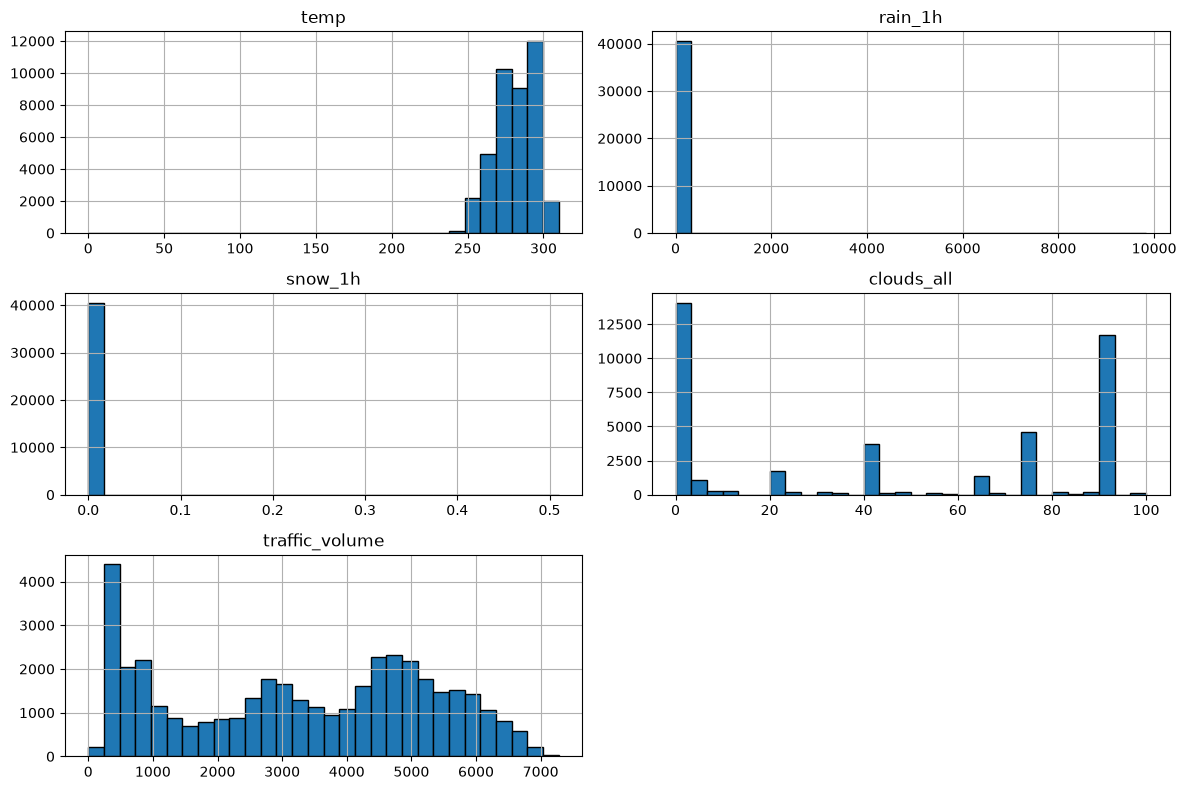

In [40]:
import matplotlib.pyplot as plt

numeric_columns = [
    "temp",
    "rain_1h",
    "snow_1h",
    "clouds_all",
    "traffic_volume"
]

df_clean[numeric_columns].hist(
    figsize=(12, 8),
    bins=30,
    edgecolor="black"
)

plt.tight_layout()
plt.show()

 the histograms show that the variables have different distribution patterns. Rainfall and snowfall contain many zero values, while traffic volume has substantial variation. These patterns will help guide our feature selection and forecasting preparation.